## 与NYISO的预测结果对比
取 2025 年整点的预测，和 `forecast_2025.csv` 里 `zone == 'CAPITL'` 的官方预测按时间合并，在同一批行上比较两边的 MAPE、RMSE、MAE、R²。

### 1. 数据合并

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score
%matplotlib inline

In [2]:
pred_captial_2025 = pd.read_csv('pred_captial_2025.csv', parse_dates=['timestamp'])
# 只留整点
pred_captial_2025 = pred_captial_2025[(pred_captial_2025.timestamp.dt.minute == 0) & (pred_captial_2025.timestamp.dt.second == 0)]

与NYISO预测数据合并

In [3]:
fc = pd.read_csv('../data/nyiso_dayahead_forecasts/forecast_2025.csv', parse_dates=['timestamp'])
# 只取 Capital 区；官方预测在夏令时回拨那天有 1 个重复时间
fc = fc[fc.zone == 'CAPITL'].drop_duplicates(subset=['timestamp'])

with_forecast = pred_captial_2025.merge(fc[['timestamp', 'forecast']], on='timestamp')

In [ ]:
# len(...) 返回行数，应该是 8759（2025 年有 8760 个小时，夏令时拨快那天少一个）。
print(len(with_forecast))
# .isna().sum() 返回每一列的空值个数，应该全是 0。
with_forecast.isna().sum()

8759


timestamp       0
load            0
temperaturef    0
t_m48           0
prediction      0
forecast        0
dtype: int64

### 2. 整体指标对比

In [6]:
def score_row(name, y_true, y_pred):
    ok = y_pred.notna() # 预测值为空的行不参与计算
    y_true, y_pred = y_true[ok], y_pred[ok]
    return {
        '模型':name,
        'RMSE':np.sqrt(mean_squared_error(y_true, y_pred)),
        'MAE':mean_absolute_error(y_true, y_pred),
        'R2': r2_score(y_true, y_pred),
        'MAPE(%)': mean_absolute_percentage_error(y_true, y_pred) * 100,
    }

rows = [
    score_row('XGBoost', with_forecast['load'], with_forecast['prediction']),
    score_row('NYISO', with_forecast['load'], with_forecast['forecast']),
    score_row('朴素(t_m48)', with_forecast['load'], with_forecast['t_m48']),
]
pd.DataFrame(rows).sort_values('RMSE')

,模型,RMSE,MAE,R2,MAPE(%)
1,NYISO,93.379295,74.755797,0.878110,5.683190
0,XGBoost,95.216444,69.140878,0.873267,5.752057
2,朴素(t_m48),190.769897,136.367662,0.491273,10.739509


整体数字接近，下面按月看各自强在哪儿。

### 3. 按月对比

,XGBoost MAPE(%),NYISO MAPE(%)
month,,
1,4.21,6.10
2,4.39,6.18
3,7.08,6.69
4,7.49,5.77
5,7.55,6.90
6,6.52,5.42
7,5.46,5.03
8,5.74,5.17
9,5.83,4.61


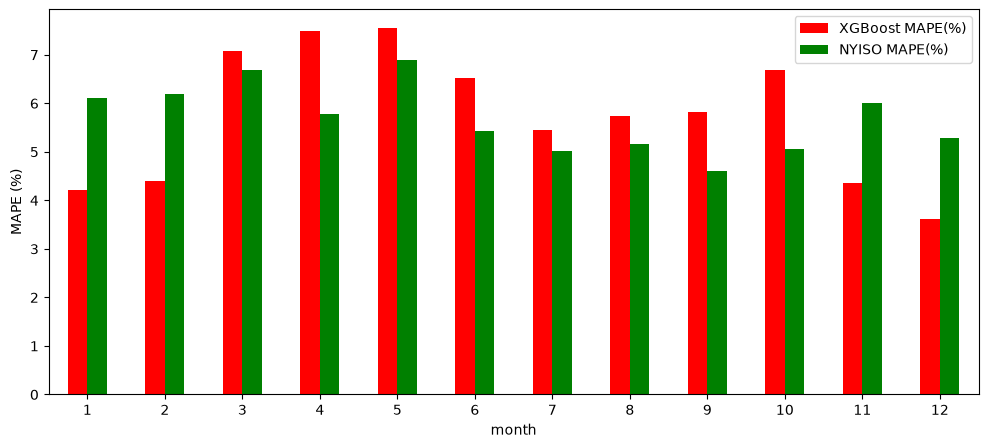

In [ ]:
# 每一行的相对误差（百分比），对应 nyiso_mape
with_forecast['ape_model'] = np.abs(with_forecast['load'] - with_forecast['prediction']) / with_forecast['load'] * 100
with_forecast['ape_nyiso'] = np.abs(with_forecast['load'] - with_forecast['forecast']) / with_forecast['load'] * 100

monthly = with_forecast.groupby(with_forecast.timestamp.dt.month)[['ape_model', 'ape_nyiso']].mean()
monthly.index.name = 'month'
monthly.columns = ['XGBoost MAPE(%)', 'NYISO MAPE(%)']

# plot.bar 画成柱状图，返回坐标轴；rot=0 让横轴的月份数字不倾斜。
ax = monthly.plot.bar(figsize=(12, 5), color=['red', 'green'], rot=0)
ax.set_ylabel('MAPE (%)')
monthly.round(2)


结果是 1、2、11、12 月我们的模型更准（约 4% 对 6%），3–10 月 NYISO 更准。

### 4. 看某几天的曲线

In [20]:
def compare_models(with_forecast, day1, day2, weather=False):
    # 截取 day1 到 day2 之间的行
    test_day = with_forecast[with_forecast.timestamp >= pd.to_datetime(day1)]
    test_day = test_day[test_day.timestamp < pd.to_datetime(day2)]

    # 这一段时间内两边各自的 MAPE 和 R²
    mape = mean_absolute_percentage_error(test_day['load'], test_day['prediction']) * 100
    score = r2_score(test_day['load'], test_day['prediction'])
    nyiso_mape = mean_absolute_percentage_error(test_day['load'], test_day['forecast']) * 100
    nyiso_score = r2_score(test_day['load'], test_day['forecast'])

    # {0:.3f} 表示填入第一个数、保留三位小数。
    fig, ax = plt.subplots(figsize=(18, 8))
    ax.plot(test_day.timestamp, test_day.load, label='actual load', color='blue', linewidth=3)
    ax.plot(test_day.timestamp, test_day.prediction, ls='dashed', lw=2, color='red',
            label='XGBoost, R^2 = {0:.3f}, MAPE = {1:.2f}%'.format(score, mape))
    ax.plot(test_day.timestamp, test_day.forecast, ls='dashed', lw=2, color='green',
            label='NYISO day ahead forecast, R^2 = {0:.3f}, MAPE = {1:.2f}%'.format(nyiso_score, nyiso_mape))

    if weather == True:
        ax2 = ax.twinx() # ax.twinx() 在同一张图上再加一条右侧的纵轴，用来画气温，只有 weather=True 时才画。
        ax2.plot(test_day.timestamp, test_day.temperaturef, label='temperature', color='orange', alpha=.5)
        ax2.set_ylabel('temperature (F)', fontsize=16)

    ax.legend(loc='best')
    ax.set_title(day1 + ' - ' + day2 + '\nNYISO Capital Region', fontsize=20)
    ax.set_xlabel('time', fontsize=16)
    ax.set_ylabel('load (megawatts)', fontsize=16)
    return ax


<Axes: title={'center': '2025-01-19 - 2025-01-26\nNYISO Capital Region'}, xlabel='time', ylabel='load (megawatts)'>

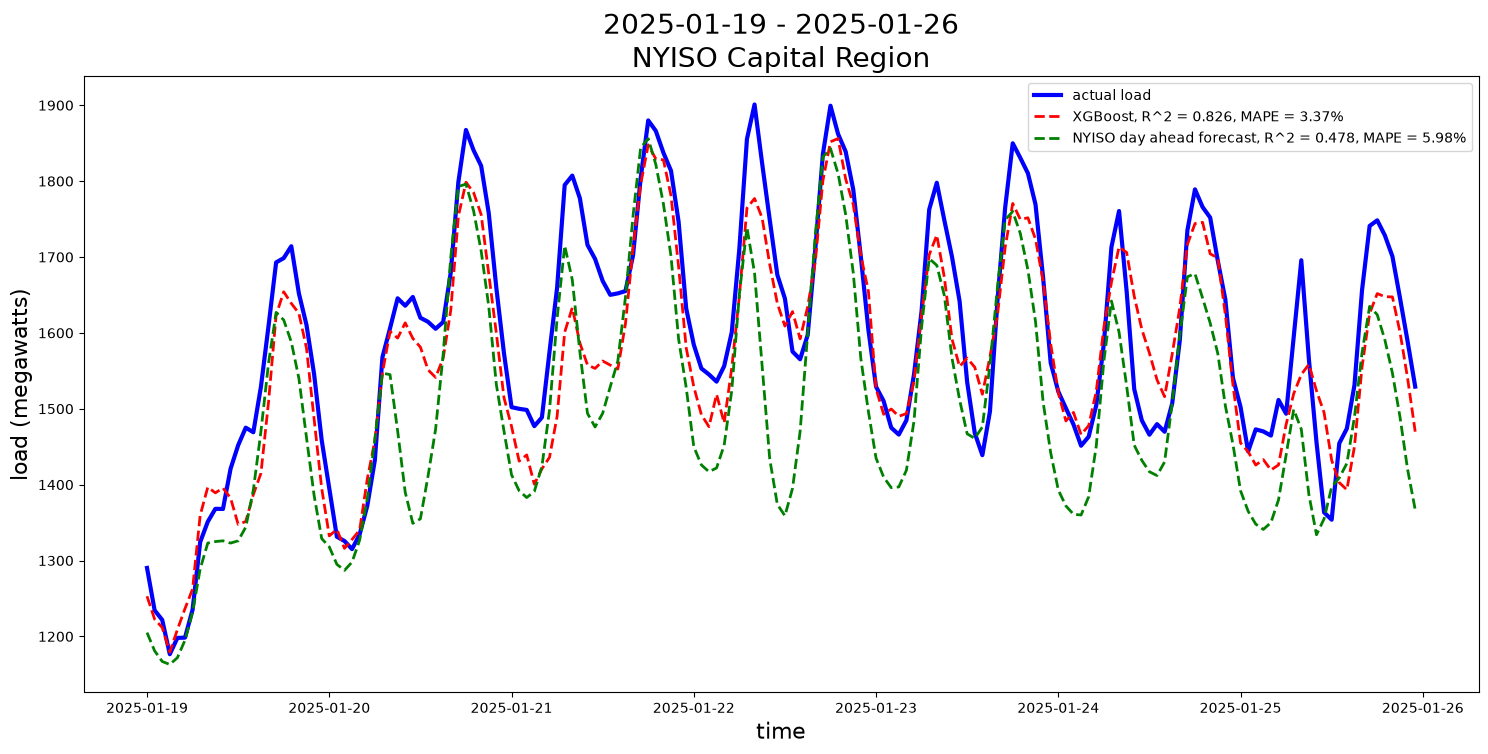

In [21]:
compare_models(with_forecast, '2025-01-19', '2025-01-26')

<Axes: title={'center': '2025-07-13 - 2025-07-20\nNYISO Capital Region'}, xlabel='time', ylabel='load (megawatts)'>

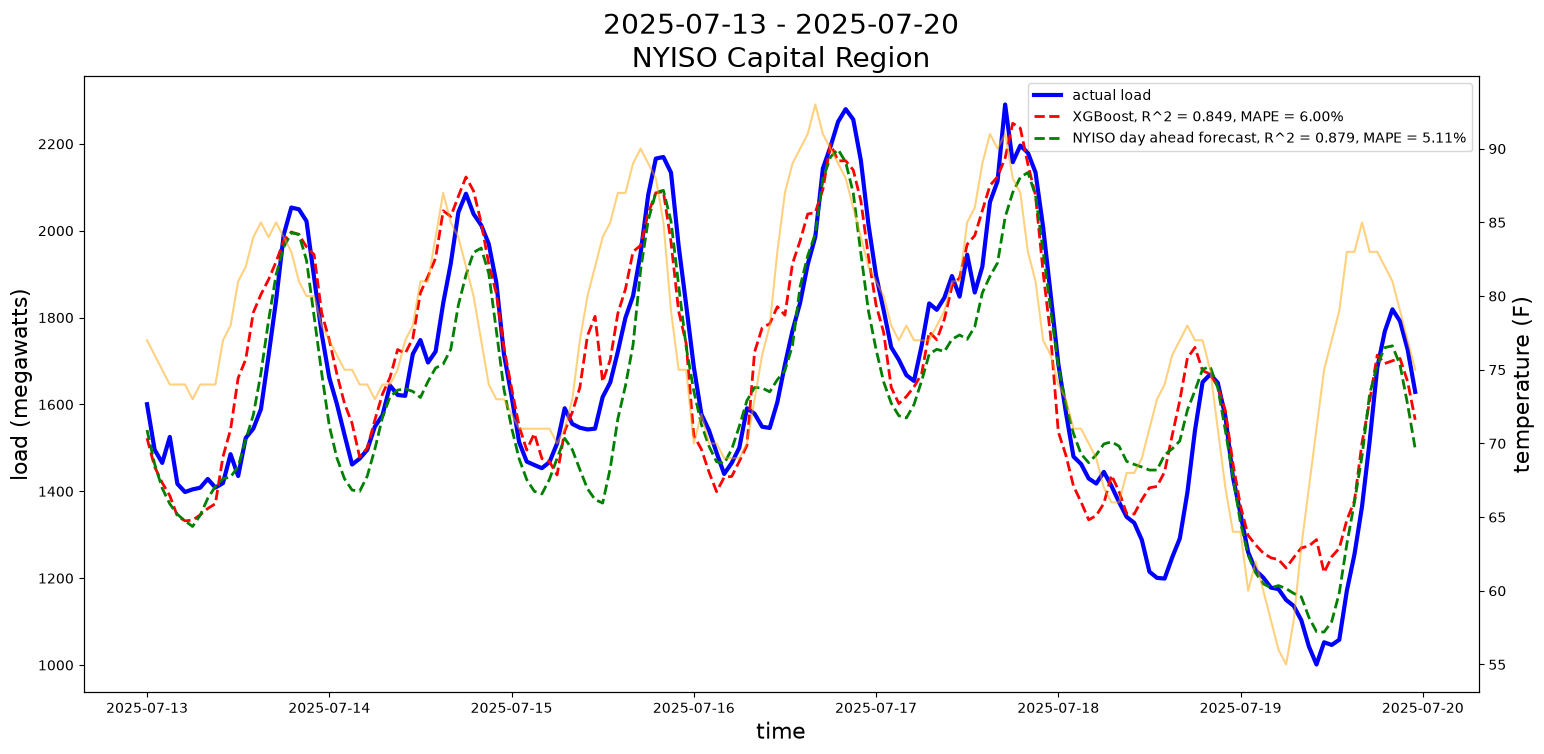

In [22]:
compare_models(with_forecast, '2025-07-13', '2025-07-20', weather=True)

<Axes: title={'center': '2025-04-13 - 2025-04-20\nNYISO Capital Region'}, xlabel='time', ylabel='load (megawatts)'>

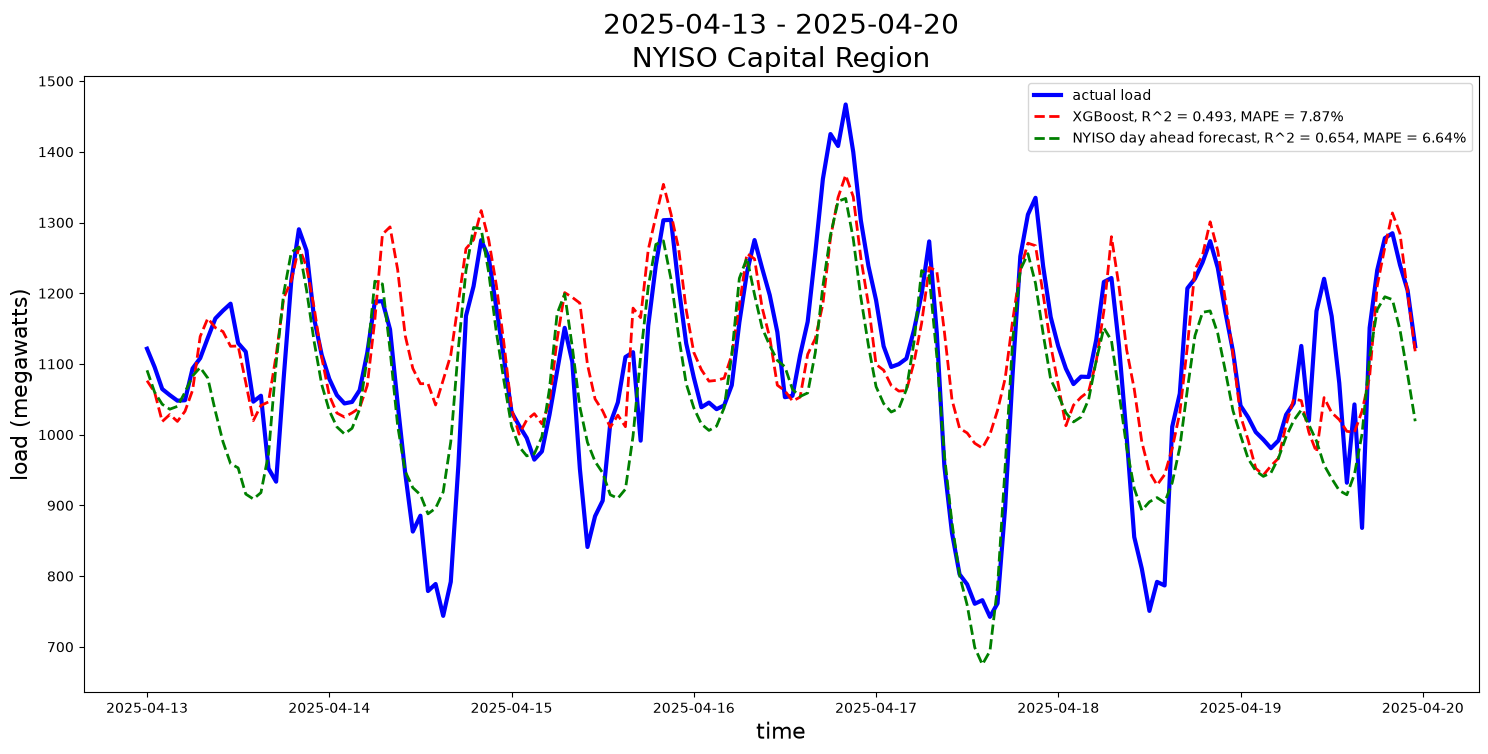

In [23]:
compare_models(with_forecast, '2025-04-13', '2025-04-20')

### 5.全年曲线

In [ ]:
# set_index('timestamp') 把时间设成行索引，按时间分组需要这样。
p = with_forecast.set_index('timestamp') 
# pd.Grouper(freq='4D') 表示每 4 天分一组，是 6 号里 pd.TimeGrouper 的新写法；.median() 对每组取中位数，得到 92 行的表。
smooth = p[['load', 'prediction', 'forecast']].groupby(pd.Grouper(freq='4D')).median()
smooth

,load,prediction,forecast
timestamp,,,
2025-01-01,1404.94365,1356.91360,1377.0
2025-01-05,1583.96685,1516.86360,1543.5
2025-01-09,1470.11270,1480.72365,1466.0
2025-01-13,1500.12845,1499.59860,1423.5
2025-01-17,1501.60520,1425.71410,1368.5
...,...,...,...
2025-12-15,1571.88865,1556.57055,1508.0
2025-12-19,1423.07390,1418.57405,1379.0
2025-12-23,1481.28755,1496.68795,1398.5


Text(0, 0.5, 'Load (Megawatts)')

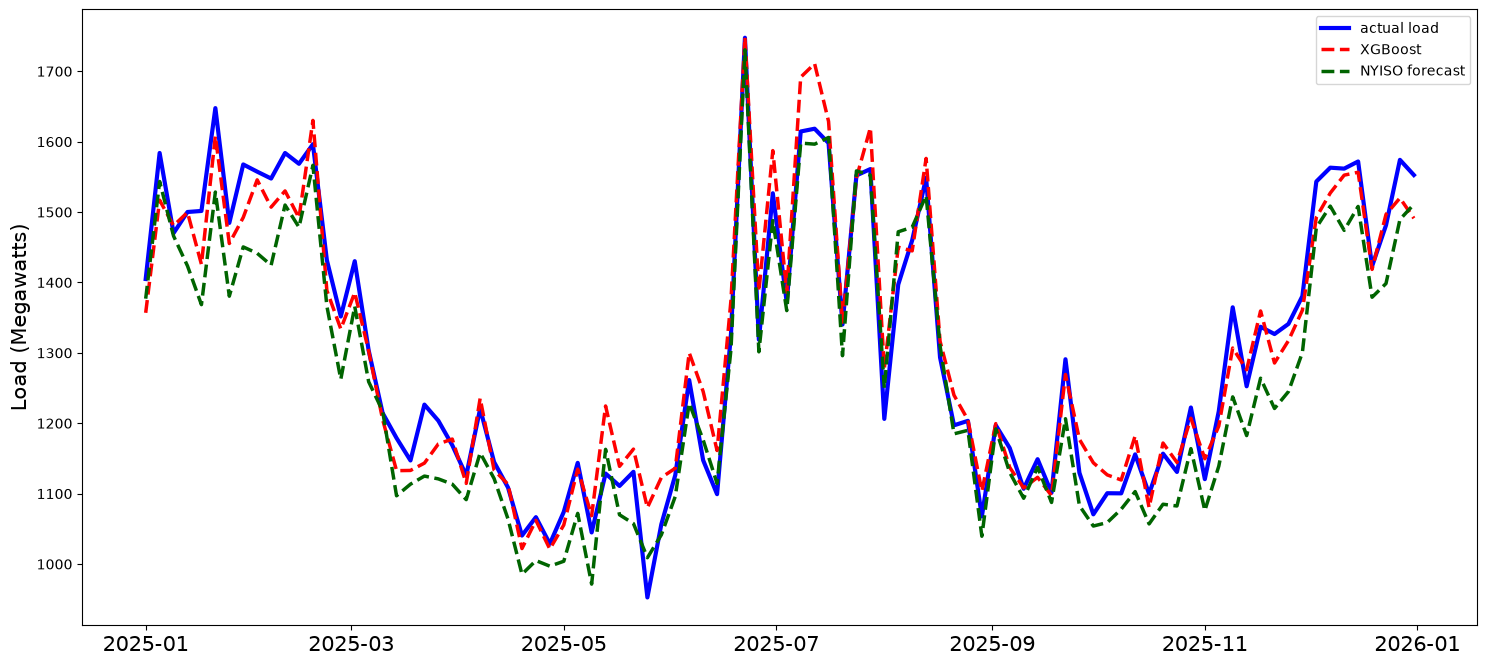

In [25]:
fig, ax1 = plt.subplots(figsize=(18, 8))
ax1.plot(smooth.index, smooth['load'], color='blue', label='actual load', lw=3)
ax1.plot(smooth.index, smooth['prediction'], color='red', label='XGBoost', lw=2.5, ls='dashed')
ax1.plot(smooth.index, smooth['forecast'], color='darkgreen', label='NYISO forecast', lw=2.5, ls='dashed')
ax1.legend(loc='best')
ax1.tick_params(axis='x', labelsize=15)
ax1.set_ylabel('Load (Megawatts)', fontsize=15)

### 6. 总结

#### (1) 这个 notebook 做了什么

把上一个 notebook 里 XGBoost 对 2025 年 Capital 区的预测，和 NYISO 官方的提前一天预测放在一起比较。

1. **数据**：`pred_captial_2025.csv`（我们的预测，5 分钟一条）和 `forecast_2025.csv`（官方预测，逐小时）。
2. **对齐**：我们的预测只留整点的行，官方预测只取 `zone == 'CAPITL'`，按时间合并，得到 8759 行，没有空值。
3. **比较**：两边都和同一批行的真实负荷比，先看全年的四个指标，再按月看，最后画几段时间和全年的曲线。

#### (2) 结果

| 模型 | RMSE | MAE | R² | MAPE |
|---|---|---|---|---|
| NYISO | **93.4** | 74.8 | **0.878** | **5.68%** |
| XGBoost | 95.2 | **69.1** | 0.873 | 5.75% |
| 朴素（`t_m48`） | 190.8 | 136.4 | 0.491 | 10.74% |

RMSE 和 MAE 的单位是兆瓦。

#### (3) 结论

- **两边基本打平。** NYISO 在 RMSE、R²、MAPE 上略好，我们的模型在 MAE 上更好，差距都很小；两边都远好于朴素 baseline。
- **冬天我们更准，其余时间 NYISO 更准。** 1、2、11、12 月我们的 MAPE 是 3.6%–4.4%，NYISO 是 5.3%–6.2%；3–10 月 NYISO 每个月都更准，差距最大的是 4 月（7.5% 对 5.8%）和 10 月（6.7% 对 5.1%）。
- **具体到某一周也是这样。** 1 月 19–26 日我们的 MAPE 是 3.4%，NYISO 是 6.0%；7 月 13–20 日是 6.0% 对 5.1%；4 月 13–20 日是 7.9% 对 6.6%。
- **两边出错的方式不同。** 另行统计过：NYISO 的预测全年平均比真实负荷低 43 兆瓦，冬季低约 70–80 兆瓦；我们的预测平均只偏高 8 兆瓦。在电力需求预测上，一般偏高的收益要高于偏低，因为临时购电成本更大，从这个角度看，我们的模型表现更好。按小时看，58% 的小时我们更接近真实值，但我们的大误差更多（偏差超过 200 兆瓦的小时占 5.9%，NYISO 是 3.1%）。这就是我们 MAE 更好、RMSE 却更差的原因。
- **和原项目的结论一致。** 原作者用 GBR 在 2014–2016 年上的 MAPE 是 4.80%，NYISO 是 4.67%，同样是接近但略逊。

#### (4) 读这些数字时要注意的地方

- **我们用的是实测气温。** NYISO 做预测时只能用天气预报，所以这个对比对我们有利。真正上线预测时要换成天气预报，误差会变大。
- **NYISO 的预测整体偏低，原因没有查明。** 可能是两份数据的统计口径不同。如果是这样，它的误差里有一部分不是预测不准造成的。
- **只比了一年、一个区域。** 换一年或换一个区域，谁好谁差可能不同。
- **夏令时那两天有少量时间对不上。** 拨快那天少一个小时，回拨那天官方预测有一个重复时间，已去重，影响可以忽略。

#### (5) 可以继续做的事

- 重点改进 3–10 月：这段时间负荷本身低，同样的兆瓦误差会带来更高的百分比误差，可以试着加入节假日、日照之类的特征。
- 把实测气温换成天气预报再比一次，才是和 NYISO 完全公平的对比。
- 对其余 10 个区域重复同样的流程，看结论是否一致。